# The 2μ2e background from the search plane's own sidebands

**Summary.** The 2μ2e search region holds an estimated **46 ± 15 (stat.) ± 9 (syst.)** background events
(2018 data, 59.8 fb⁻¹). The estimate is the plain ABCD method in the search plane itself: the
background in the search region, A, is predicted from the three neighbouring regions B, C and D of
the same plane as A = B·C/D = 45.7 ± 14.9 events (from 78, 17 and 29 events). That prediction is
right when the two variables that define the regions are independent for the background. We test
this in every region of the data where the corresponding A is open (not blinded): the three planes
in which at least one lepton jet is prompt, the search plane itself below 150 GeV, and the seven
validation regions of Dongyub Lee's programme, recomputed from these histograms. In the regions
measured to 20% or better the method holds within 20%; the largest deviation is in the plane where
only the egamma lepton jet is displaced (PD, κ = 1.20 ± 0.10). That deviation sets the systematic
uncertainty: 20% by the rule of section 8, 27–31% if the photon-only egamma lepton jets, which
carry PD's deviation, are taken as what decides κ of the search plane; that choice is put to the
group. The earlier notebooks borrowed a factor from that plane and quoted 61 events; here
that number is a cross-check.

**How to read this notebook.** Every number is from data unless it is marked as simulation. The
search region itself (region A of the search plane above 150 GeV, defined in section 3) is hidden:
the histograms are loaded with those cells set to NaN, any region that touches them prints as
"hidden", and nothing is computed from them. Everything else is open. Sections 1–3 explain the
method and the objects, section 4 gives the estimate, sections 5–7 test it, section 8 turns the
tests into a systematic uncertainty, sections 9–10 give the cross-checks and what would settle the
remaining question, section 11 covers 4μ, and section 12 summarises. The longer record is in
`estimate.ipynb` (the four estimate routes, the configuration scan, the simulation) and
`binning.ipynb` (the estimate per mass bin and the expected limits).

In [1]:
import dataclasses
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import abcd6d_io as io
import transfer_lib as tl
import transfer_plots as tp
import plane_search_lib as ps
import estimate_lib as el
import binning_lib as bl
import binning_plots as bp
import nominal_lib as nl
import nominal_plots as npl

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 200)
tp.set_style()

BASE = os.environ.get("ABCD8D_LOCAL", "/uscms_data/d3/murtazas/abcd8d_local")
print("8D inputs:", BASE)
data = tl.summed_cubes(BASE, "data", prefix="abcd8d")     # the only data path: hidden cells are NaN
print("hidden box:", io.blind_signature(prefix="abcd8d"))
for t, c in data.items():
    print(f"{t}: {c.sumw.shape}, {int(np.isnan(c.sumw).sum())} hidden cells")
d2, d4 = data["2mu2e"], data["4mu"]
NOMINAL, LOW, HIS_WP = nl.NOMINAL, nl.LOW, nl.HIS_WP
VRS = {v.name: v for v in nl.our_vrs()}
WINDOWS = [("M >= 150", NOMINAL),
           ("150-300", dataclasses.replace(NOMINAL, mass=(150.0, 300.0))),
           ("M >= 300", dataclasses.replace(NOMINAL, mass=(300.0, None)))]
print("nominal configuration:", NOMINAL.label())
print("Dongyub Lee's working point:", HIS_WP.label().split(", M")[0])

8D inputs: /uscms_data/d3/murtazas/abcd8d_local


hidden box: iso0<0.25 iso1<0.5 mass>=150 dphi>=2.4 planes=[('2mu2e', ('displaced', 'displaced')), ('4mu', ('displaced', 'displaced')), ('4mu', ('displaced', 'prompt')), ('4mu', ('prompt', 'displaced'))]
2mu2e: (12, 12, 6, 4, 10, 10, 8, 3), 241920 hidden cells
4mu: (12, 12, 6, 6, 10, 10, 5, 3, 3), 1360800 hidden cells
nominal configuration: dphi 2.4/2.4 x iso0 0.25/0.25, iso1<0.5, M>=150
Dongyub Lee's working point: dphi 2.6/2.6 x iso0 0.3/0.3, iso1<0.5


## 1. ABCD in one page

The ABCD method predicts a background in a region we cannot look at from three regions we can. Take
two variables, x and y, that the signal and the background distribute differently, and cut on each:
the signal sits where both cuts pass. Those two cuts split the plane of (x, y) into four regions:

* **A** passes both cuts (the search region);
* **B** fails x and passes y;
* **C** passes x and fails y;
* **D** fails both.

If x and y are independent for the background, the fraction of events that pass x is the same
whether y passes or not: A/B = C/D, equivalently A/C = B/D, and so **A = B·C/D**. B, C and D are dominated by background,
so the right-hand side can be counted in data.

The test of the assumption is the closure ratio **κ = A·D/(B·C)**, measured in a plane where A is
open: κ = 1 within its error means the method works there. "Closes" in this notebook means exactly
that, κ consistent with one within its quoted 68% interval. Two things break the method: a
correlation between x and y in the background, or a background component that lives in one corner
of the plane only (a component in A that B, C and D do not see).

*How to read the figure:* the square is the plane, with x to the right and y upwards; the shaded
corner is A.

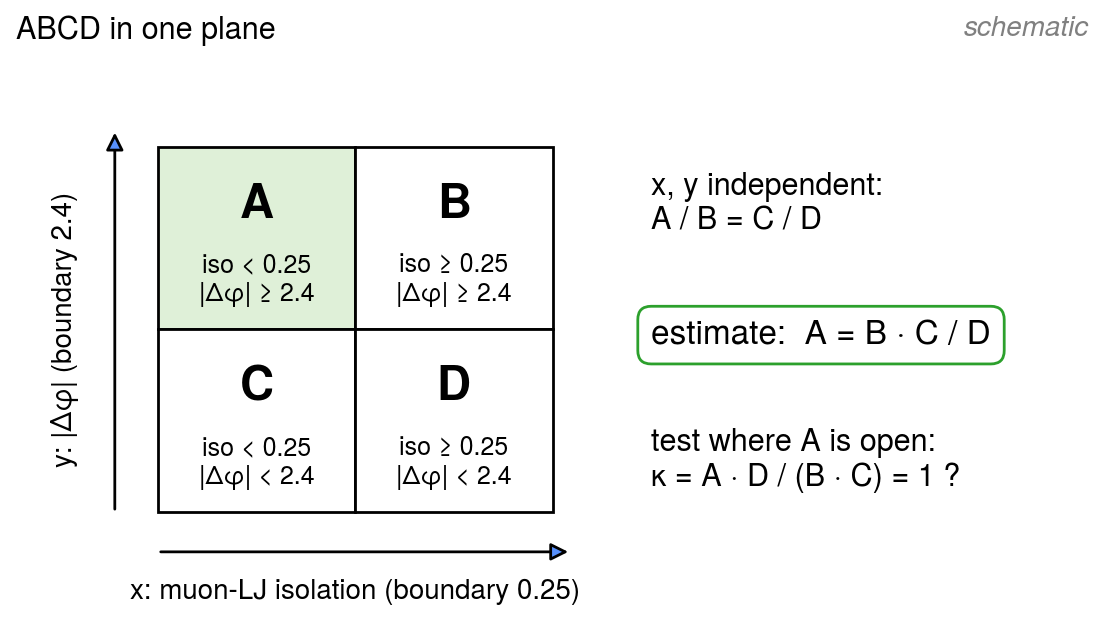

In [2]:
fig = npl.abcd_cartoon()
plt.show()

## 2. Our objects and variables

A **lepton jet (LJ)** is a cluster of collimated leptons and photons, the signature of a light
dark photon decaying to a lepton pair. A **muon LJ** is built from muons, an **egamma LJ** from
electrons and photons. A 2μ2e event has one of each.

The two ABCD variables are properties of the pair:

* **x = the muon LJ's isolation.** Take the nearest jet within ΔR < 0.4 of the muon LJ and remove
  from its energy all of its electromagnetic and muon energy (the jet's charged and neutral
  electromagnetic fractions and its muon fraction, whichever particles carry them, not only the
  LJ's own); the remainder divided by the LJ's energy is the isolation. It is 0 when no jet is near. A signal LJ is isolated;
  a muon LJ inside a QCD jet is not.
* **y = |Δφ|, the azimuthal angle between the two LJs.** The two LJs of a signal event come from
  one heavy particle at rest and are back-to-back (|Δφ| near π); background pairs are spread out.

The search region's other cuts (the validation regions relax them as stated in sections 5 and 6): the egamma LJ is isolated (its isolation, defined the same way,
< 0.5); the LJ-pair mass M(LJ, LJ) ≥ 150 GeV; both LJs displaced (section 3).

The **working point** (WP) is the pair of cuts that defines A: isolated means isolation < 0.25,
back-to-back means |Δφ| ≥ 2.4. A **sideband** is a region next to A that fails one or both cuts:
here B (isolation ≥ 0.25), C (|Δφ| < 2.4) and D. The sidebands start right at A's edges, with no
**buffer band** between them. The earlier version of `estimate.ipynb` left a buffer (B at
isolation ≥ 0.5, C and D at |Δφ| < 2.0); the buffers were most of the non-closure it saw in the
prompt plane, and were removed (`estimate.ipynb`, section 4).

*How to read the figure:* the isolation × |Δφ| distribution of the plane with both LJs prompt
(PP, section 3) above 150 GeV; colour is events per cell on a log scale, bins are drawn with equal
width with the stored edges as tick labels, the red lines are the working point, and each region's
total is written in it (797/1545/202/379 events in A/B/C/D).

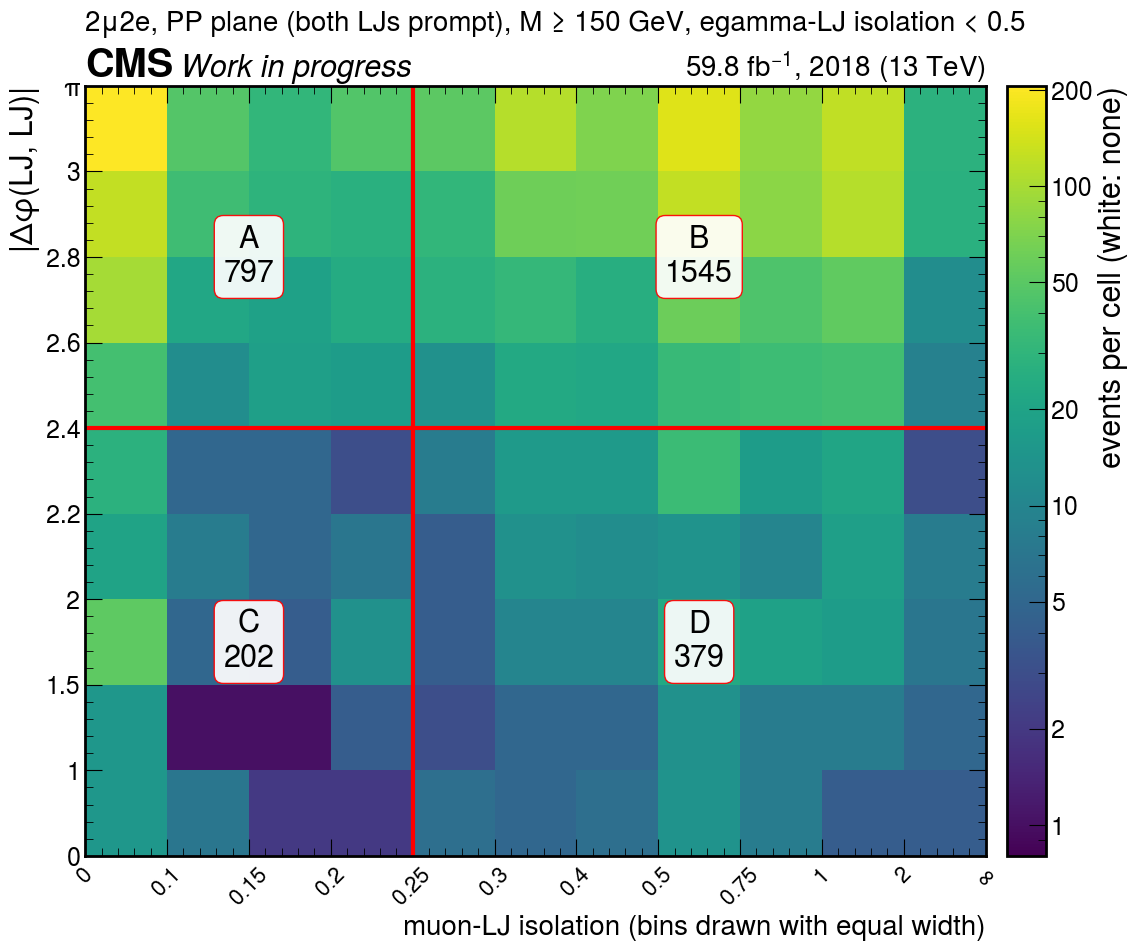

In [3]:
fig = npl.plane_figure(nl.plane_hist2d(d2, NOMINAL, "PP"), NOMINAL,
                       "2μ2e, PP plane (both LJs prompt), M ≥ 150 GeV, egamma-LJ isolation < 0.5", "nominal_plane_PP")
plt.show()

## 3. The four planes and the hidden box

Each LJ is **prompt** or **displaced**, judged from hit counts in the tracker:

* a muon LJ is displaced when the largest number of **pixel hits** (hits in the innermost tracker
  layers) over its PF muons (the muons reconstructed with a tracker track) is ≤ 2, prompt when it
  is ≥ 3. A **DSA muon** (displaced standalone muon, reconstructed from the muon chambers alone)
  adds no pixel hits, so it never makes an LJ prompt: the LJ is displaced only when none of its PF
  muons has 3 or more pixel hits, and an LJ made only of DSA muons is displaced by that rule;
* an egamma LJ is displaced when the smallest number of **lostHits** (missing hits in the inner
  tracker before the first hit of an electron's track) over its electrons is ≥ 1, prompt when it is
  0. A photon-only egamma LJ has no track and counts as displaced.

That gives four planes, named by the muon LJ first: **PP**, **PD** (muon LJ prompt, egamma LJ
displaced), **DP** and **DD**. DD is the search plane. **Blinding** means that a region where the
signal is expected is not looked at until the method is fixed. The hidden box is region A of DD
above 150 GeV: muon-LJ isolation < 0.25, egamma-LJ isolation < 0.5, |Δφ| ≥ 2.4, M(LJ, LJ) ≥
150 GeV, both LJs displaced. Its B, C and D are
open, and so is everything below 150 GeV and every other plane.

*How to read the figure:* the four planes as a 2 × 2 grid (rows: muon LJ prompt, displaced;
columns: egamma LJ prompt, displaced), each split into A (top left), B, C and D with the data
counts above 150 GeV; the hatched cell is the hidden box.

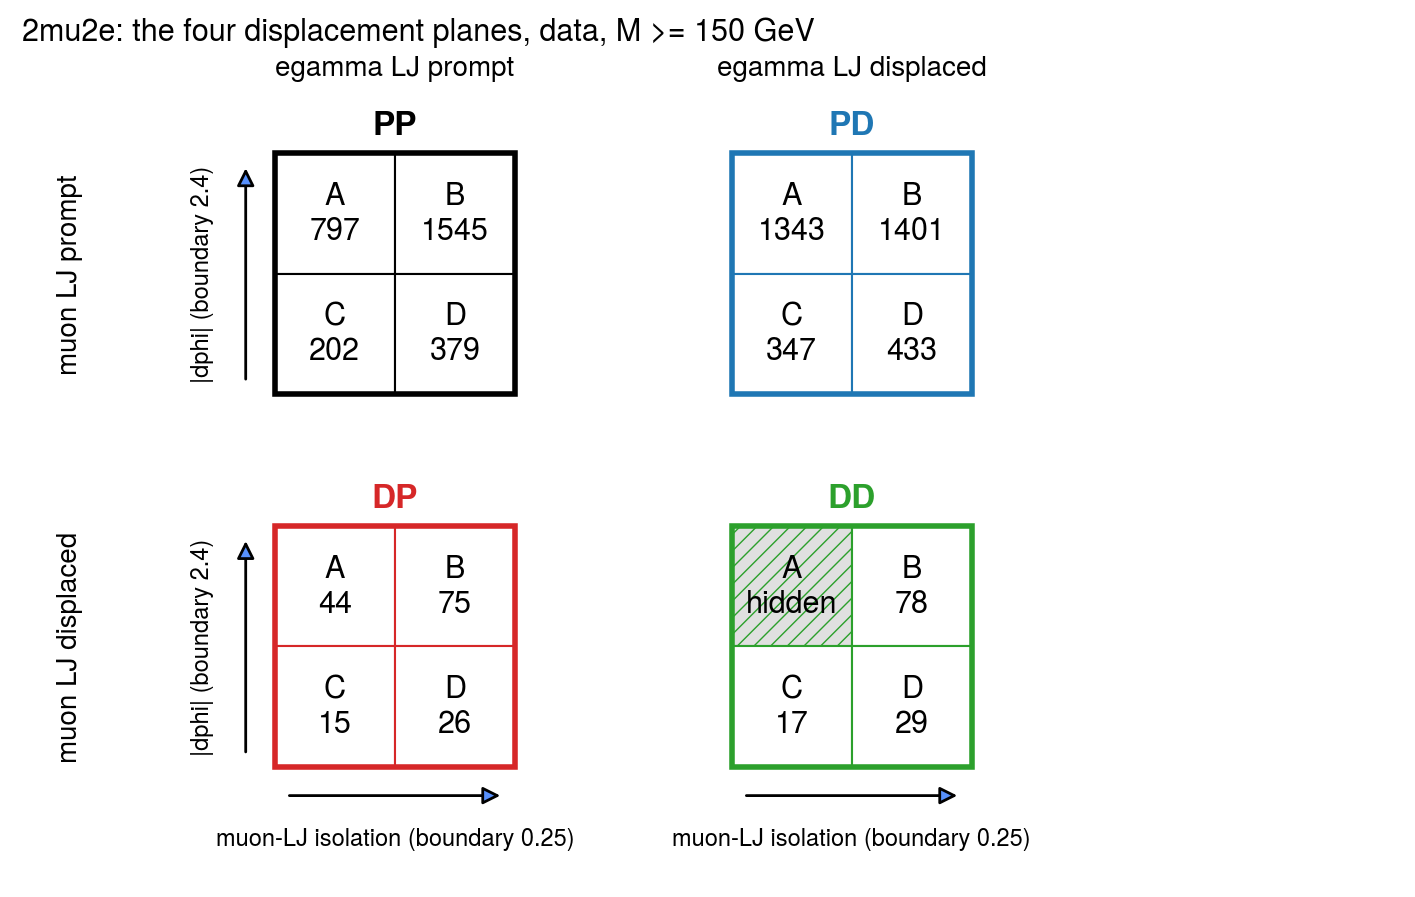

In [4]:
fig = bp.planes_cartoon(d2, NOMINAL, "2mu2e", routes=False)
plt.show()

## 4. The estimate

In DD above 150 GeV, B, C and D hold 78, 17 and 29 events, and

**A = B·C/D = 45.7 ± 14.9 events** (statistical error 33%, from the Poisson errors of the three
counts propagated through the product, as `estimate_lib` and `plane_search_lib` do it).

The table gives the counts and the prediction; κ cannot be computed because A is hidden. This
number assumes κ = 1 in the search plane above 150 GeV. The rest of the notebook is about how well
that is justified and what uncertainty to assign to it.

*How to read the figure:* as in section 2, for the search plane; the hatched cells are the hidden
box and region A reads "hidden".

,region,definition,A,B,C,D,B C/D,kappa,precision
0,search region,"D / D, egamma iso < 0.5, M ≥ 150 GeV",hidden,78,17,29,45.7 ± 14.9,hidden (A in the box),n/a


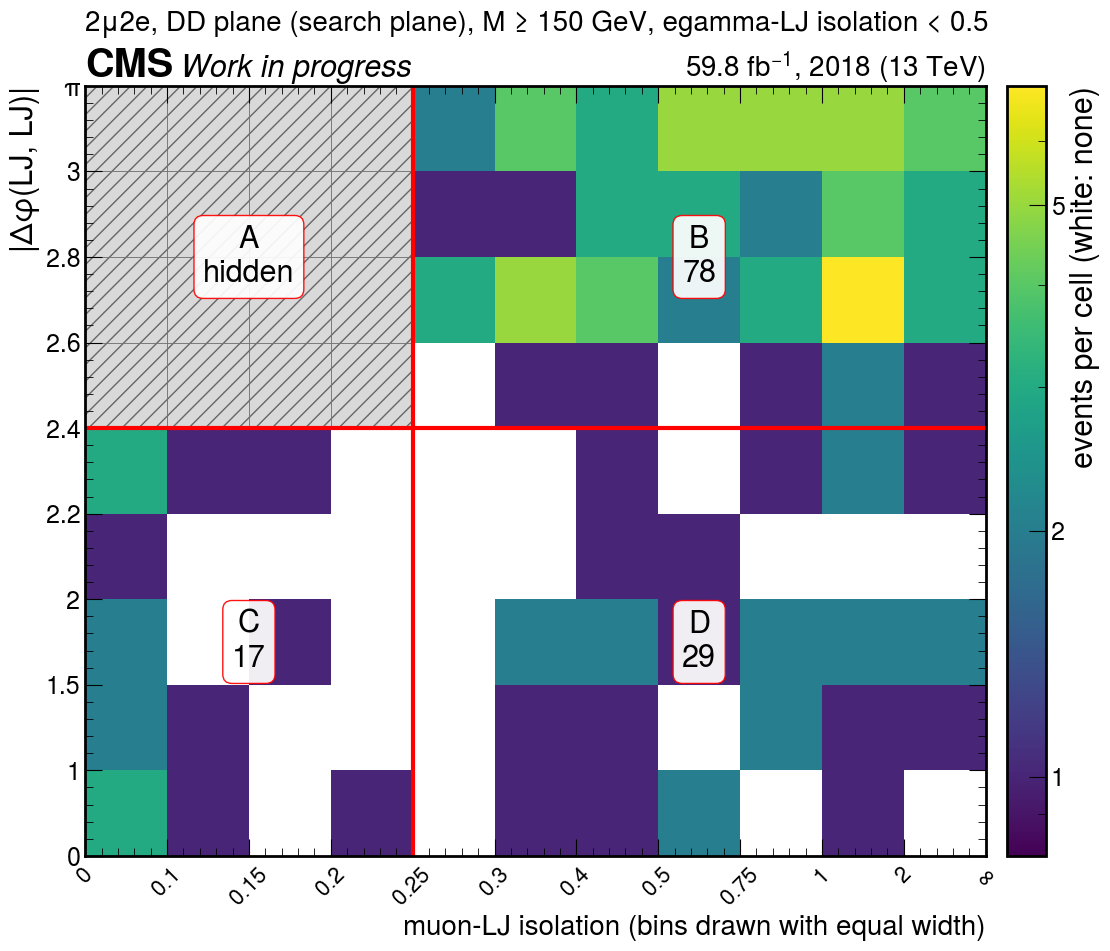

In [5]:
display(nl.kappa_view(nl.kappa_table(d2, [nl.SR], NOMINAL)))
fig = npl.plane_figure(nl.plane_hist2d(d2, NOMINAL, "DD"), NOMINAL,
                       "2μ2e, DD plane (search plane), M ≥ 150 GeV, egamma-LJ isolation < 0.5", "nominal_plane_DD")
plt.show()

## 5. Validation 1: κ wherever A is open

A **validation region** is a region like the search region whose A can be looked at. Four come
for free: the planes PP, PD and DP above 150 GeV, and the search plane itself below 150 GeV. The
table gives A, B, C, D, the prediction B·C/D and κ with its 68% interval (Clopper–Pearson
intervals of the two ratios A/C and B/D, combined); "precision" is the larger side of the interval
over κ.

* PP closes: κ = 0.97 ± 0.10 (797/1545/202/379).
* PD is 20% above one, 2.0 standard deviations: κ = 1.20 ± 0.10 (1343/1401/347/433).
* DP, κ = 1.02 -0.41 +0.48 (44/75/15/26), and DD below 150 GeV, κ = 1.26 ± 0.44 (41/32/53/52), are consistent with
  one but imprecise: their errors are 35%–47% of the value, so they cannot tell 1.0 from 1.3.

*How to read the figure:* κ per plane with its 68% interval; the dashed line is κ = 1.

,region,definition,A,B,C,D,B C/D,kappa,precision
0,PP,"P / P, egamma iso < 0.5, M ≥ 150 GeV",797,1545,202,379,823.5 ± 74.7,0.97 ± 0.10,10%
1,PD,"P / D, egamma iso < 0.5, M ≥ 150 GeV",1343,1401,347,433,1122.7 ± 86.3,1.20 ± 0.10,8%
2,DP,"D / P, egamma iso < 0.5, M ≥ 150 GeV",44,75,15,26,43.3 ± 14.9,1.02 -0.41 +0.48,47%
3,DD < 150,"D / D, egamma iso < 0.5, M < 150 GeV",41,32,53,52,32.6 ± 8.6,1.26 ± 0.44,35%


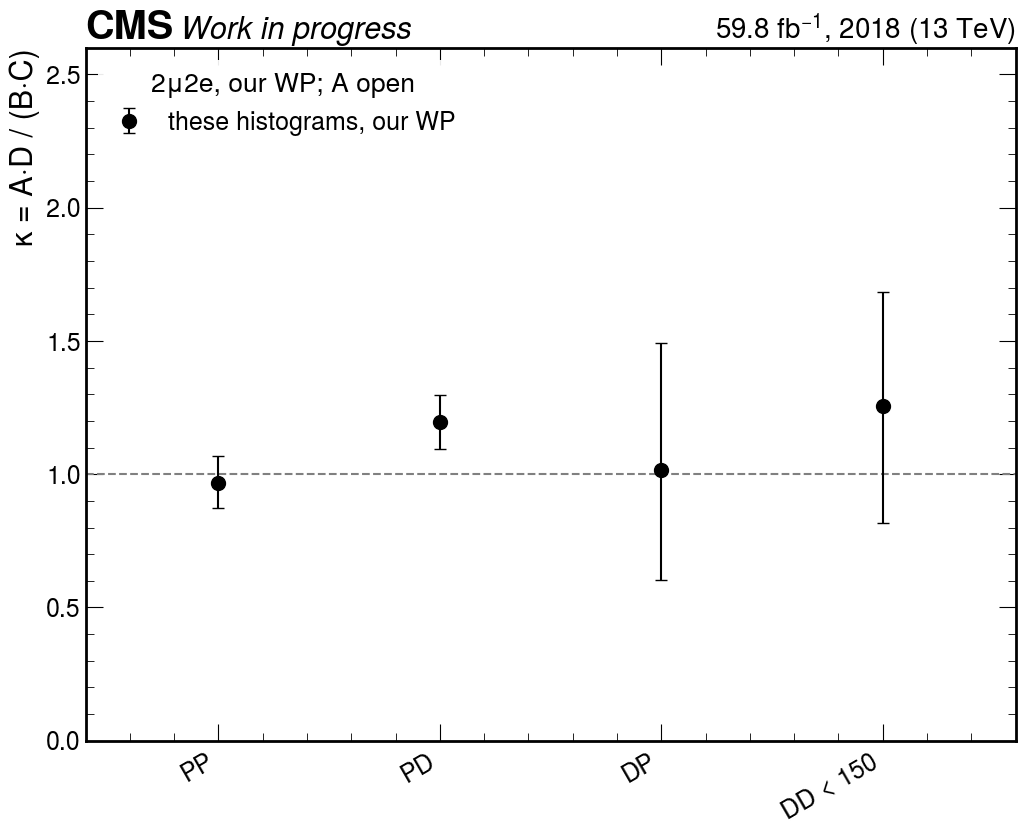

In [6]:
VAL1 = nl.kappa_table(d2, [VRS[n] for n in ("PP", "PD", "DP", "DD < 150")], NOMINAL)
display(nl.kappa_view(VAL1))
fig = npl.kappa_points_figure(*npl.table_points(VAL1), "2μ2e, our WP; A open", "nominal_kappa_open", ylim=(0, 2.6), width=12)
plt.show()

## 6. Validation 2: the seven validation regions of Dongyub Lee's programme

Dongyub Lee tested the same plane (muon-LJ isolation × |Δφ|) in seven data validation regions
(slides of 2026-10-13 and 2026-10-16), with his own analysis code. The table defines them: the
displacement of each LJ (P prompt, D displaced, "any" = either), the egamma-LJ isolation band and
the mass window. His working point is isolation < 0.3 and |Δφ| ≥ 2.6 (ours: < 0.25 and ≥ 2.4);
V1 keeps the egamma LJ isolated (< 0.5); V2–V4 put it in a non-isolated band (≥ 1 or ≥ 0.75),
which keeps their A away from the signal; V5–V7 use bands, 0.2–1 and 0.15–1, that straddle the
isolation boundary 0.5 of the search region, so they hold isolated and non-isolated egamma LJs
alike (V7 overlaps V1 in 0.15–0.5). At our working point V1 selects exactly the events of PP (797/1545/202/379 in A/B/C/D), so the two are one validation region, not two. We recompute all seven from our histograms at his
working point and at ours.

* **At his working point** the slides read 1.03/1.01/1.02/1.01/1.07/1.05/1.05, these histograms 1.03/1.01/1.02/1.01/1.07/1.05/1.06 (errors
  0.06–0.09): equal to the printed digit in 6 of 7 regions; the exception is V7, which reads 1.057 here against 1.05 on the slides. The A counts agree
  within 0.0%–0.6%. This is two codes on one data set: a cross-check of both codes,
  not an independent measurement. The A counts differ by selection details we cannot remove (our
  HEM15/16 veto applies to runs ≥ 319077 only, his to every run; our raw-event pre-filter; our
  isolation clipped at zero).
* **At our working point** the same regions read 0.97/0.87/0.88/0.93/1.05/1.03/1.03. The three low-mass regions V2–V4 read
  0.87–0.93 against 1.01–1.02 at his: κ moves by 8%–13% with the working point
  there, 1.1–1.6 standard deviations of the measurement. "Closes" is a statement at a working
  point. The four regions above 150 GeV read 0.97–1.05 at ours.
* None of the seven touches the hidden box. His working point applied to the search plane puts
  A and C of DD inside the box (C then reaches into 2.4 ≤ |Δφ| < 2.6 at isolation
  < 0.25): there is no DD estimate at his working point, as the second table shows.

*How to read the figure:* κ per region from the slides (grey squares), from these histograms at
his working point (orange diamonds) and at ours (black circles); the dashed line is κ = 1.

,region,"definition (muon LJ / egamma LJ, egamma iso, M)","kappa, slides","kappa, these histograms at his WP","kappa, these histograms at our WP",A slides / ours (his WP),A ours (our WP)
0,V1,"P / P, egamma iso < 0.5, M ≥ 150 GeV",1.03 ± 0.09,1.03 ± 0.09,0.97 ± 0.10,819 / 821,797
1,V2,"P / any, egamma iso ≥ 1, M < 150 GeV",1.01 ± 0.09,1.01 ± 0.09,0.87 ± 0.09,565 / 566,529
2,V3,"any / P, egamma iso ≥ 0.75, M < 150 GeV",1.02 ± 0.08,1.02 ± 0.09,0.88 ± 0.08,622 / 622,576
3,V4,"any / any, egamma iso ≥ 0.75, M < 150 GeV",1.01 ± 0.07,1.01 ± 0.07,0.93 ± 0.07,860 / 862,822
4,V5,"P / any, egamma iso 0.2–1, M ≥ 150 GeV",1.07 ± 0.07,1.07 ± 0.07,1.05 ± 0.08,1680 / 1685,1651
5,V6,"P / any, egamma iso 0.15–1, M ≥ 150 GeV",1.05 ± 0.06,1.05 ± 0.06,1.03 ± 0.07,1870 / 1878,1843
6,V7,"P / P, egamma iso 0.15–1, M ≥ 150 GeV",1.05 ± 0.08,1.06 ± 0.09,1.03 ± 0.10,1020 / 1026,990


the search region at both working points


,region,"definition (muon LJ / egamma LJ, egamma iso, M)","kappa, slides","kappa, these histograms at his WP","kappa, these histograms at our WP",A slides / ours (his WP),A ours (our WP)
0,search region,"D / D, egamma iso < 0.5, M ≥ 150 GeV",,hidden (A and C in the box),hidden (A in the box),hidden,hidden


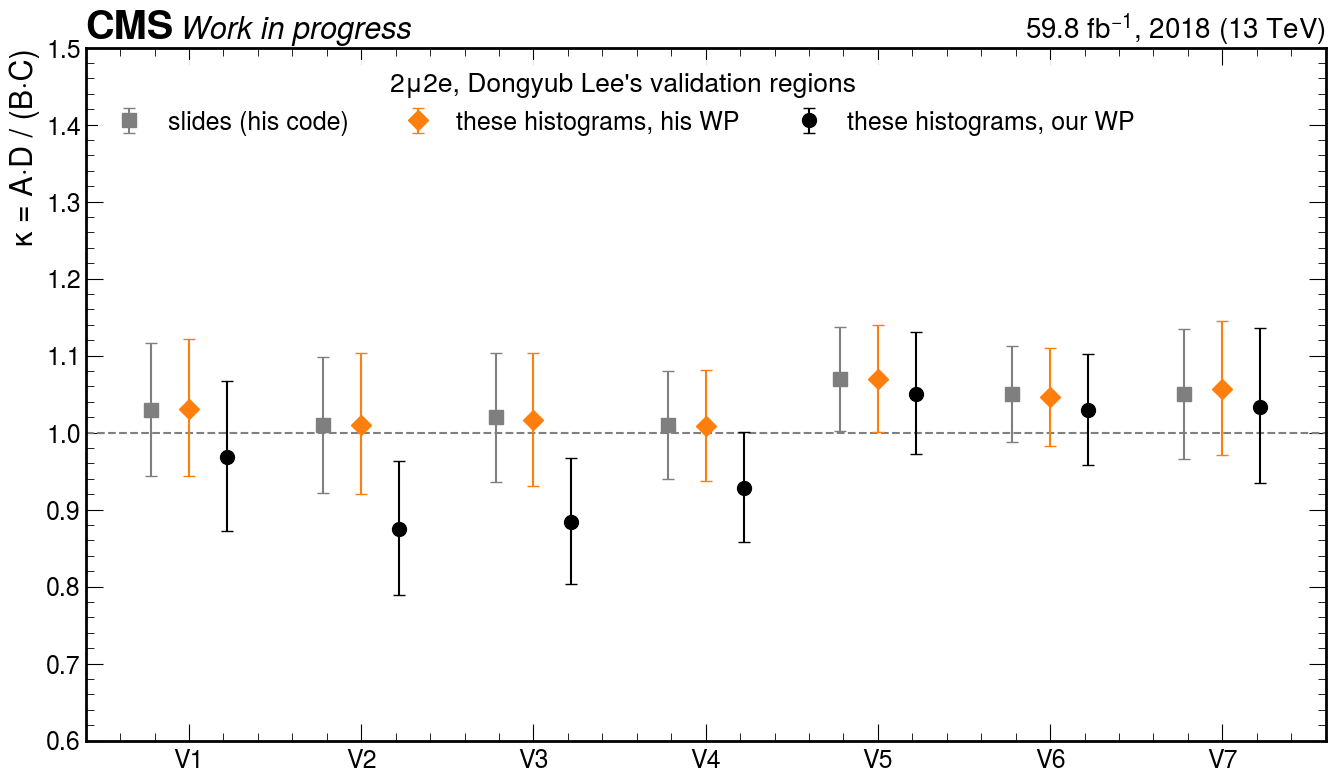

In [7]:
VRT = nl.vr_table(d2, nl.DONGYUB_VRS)
display(nl.vr_comparison_view(VRT))
print("the search region at both working points")
display(nl.vr_comparison_view(nl.vr_table(d2, (nl.SR,))))
fig = npl.kappa_points_figure(*npl.vr_points(VRT), "2μ2e, Dongyub Lee's validation regions", "nominal_kappa_dongyub",
                              ylim=(0.6, 1.5))
plt.show()

## 7. Validation 3: does κ depend on what differs between the validation regions and the search region?

The search region differs from every validation region in at least one respect. If κ depends on
one of them, the validation regions can mislead. Five checks.

### 7a. The displacement ladder

From PP (no displaced LJ) through PD and DP (one) to DD below 150 GeV (two): κ = 0.97 ± 0.10,
1.20 ± 0.10, 1.02 -0.41 +0.48, 1.26 ± 0.44. Nothing trends with the number of displaced LJs beyond the errors; the
two-displaced point carries a 35% error.

*How to read the figure:* κ against the number of displaced LJs in the plane; the dashed line is
κ = 1.

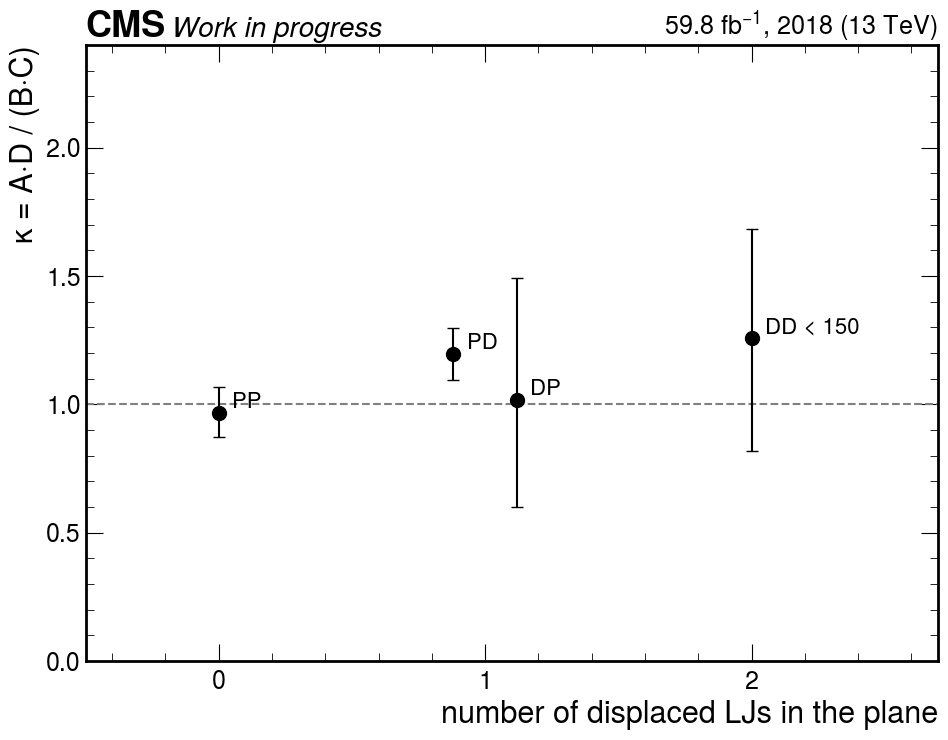

In [8]:
fig = npl.ladder_figure([(r["region"], {"PP": 0, "PD": 1, "DP": 1, "DD < 150": 2}[r["region"]],
                          (r["kappa"], r["minus"], r["plus"])) for _, r in VAL1.iterrows()])
plt.show()

### 7b. The egamma LJ type

PD's deviation sits in its photon-only egamma LJs: κ = 1.27 ± 0.12 for them, 0.77 ± 0.20 for the electron
ones. Photon-only egamma LJs count as displaced (no track, section 3), so no prompt plane contains
them; they enter PD and DD only. The photon-only share per region is 90%/86%/87%/88% in A/B/C/D of PD and
88%/94%/83% in B/C/D of DD: summed over B, C and D, DD's sidebands (88% photon-only) are
as photon-rich as PD's (86%). If κ follows the photon-only share, κ of DD is more likely to sit near
PD's 1.20 ± 0.10 than near PP's 0.97 ± 0.10. That is the case the systematic of section 8 has to cover.

*How to read the figure:* the photon-only share of the egamma LJs in each region of PD (blue) and
DD (green), with binomial errors and the number of events in brackets; A of DD is hidden.

,plane,b-tag,A,B,C,D,A/B,B/D,C/D,kappa,N_eff A
0,PD,all,1343,1401,347,433,0.96 ± 0.04,3.24 -0.18 +0.19,0.80 -0.06 +0.06,1.20 ± 0.10,1343
1,PD:g,all,1207,1201,301,381,1.00 ± 0.04,3.15 -0.19 +0.20,0.79 -0.06 +0.07,1.27 ± 0.12,1207
2,PD:e,all,136,200,46,52,0.68 -0.08 +0.08,3.85 -0.59 +0.70,0.88 -0.18 +0.22,0.77 ± 0.20,136


,plane,region,events,e,g
0,PD,A,1343,136 (10%),1207 (90%)
1,PD,B,1401,200 (14%),1201 (86%)
2,PD,C,347,46 (13%),301 (87%)
3,PD,D,433,52 (12%),381 (88%)
4,DD,A,hidden,hidden,hidden
5,DD,B,78,9 (12%),69 (88%)
6,DD,C,17,1 (6%),16 (94%)
7,DD,D,29,5 (17%),24 (83%)


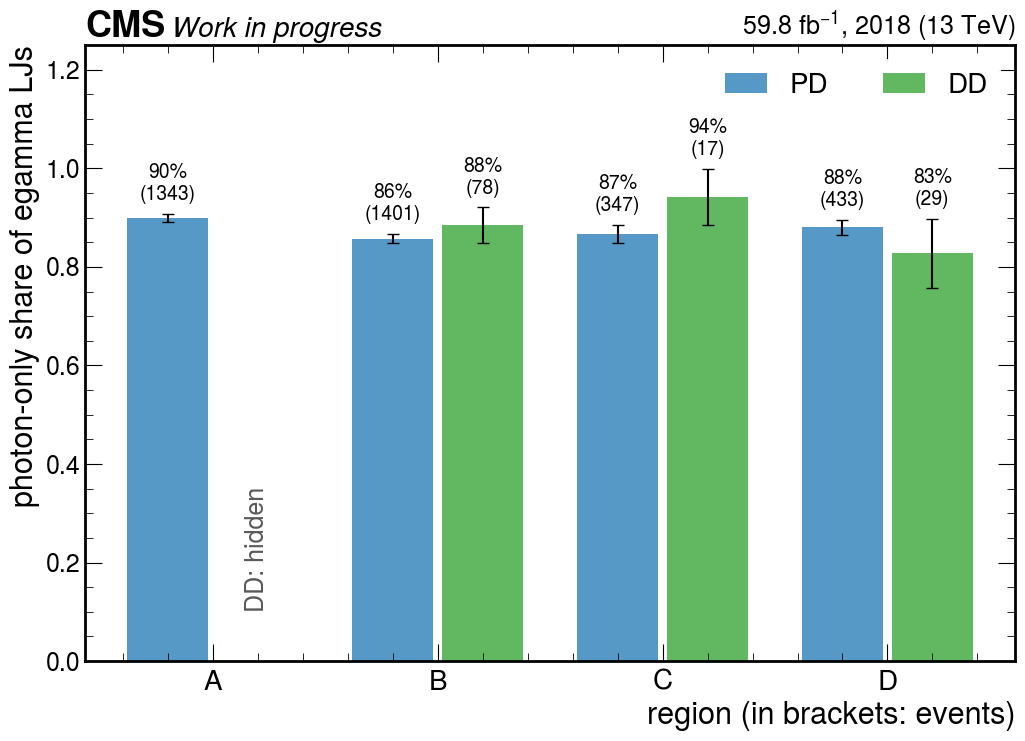

In [9]:
display(el.class_grid_table(d2, NOMINAL, ("PD",), (None, "g", "e")))
SHARES_G = nl.class_share_table(d2, NOMINAL, ("PD", "DD"), ("e", "g"))
display(nl.class_share_view(SHARES_G, ("e", "g")))
fig = npl.photon_share_figure(SHARES_G)
plt.show()

### 7c. The muon LJ's DSA class

A muon LJ with a DSA muon (class `dsa1+`) is a different object from one without (`dsa0`). κ per
class: PP 1.02 ± 0.11 (`dsa0`) and 0.59 -0.18 +0.20 (`dsa1+`), PD 1.24 ± 0.11 and 0.73 -0.17 +0.19. The
`dsa1+` share of B/C/D is 14%/13%/17% in PD and 44%/29%/45% in DD. The two classes' κ differ by
1.9 standard deviations in PP and 2.3 in PD. In both planes κ of the `dsa1+` class is the lower one. DD's sidebands hold
2.2–3.1 times PD's `dsa1+` share, so if the class difference carries over to DD it pulls κ of DD
down, from 1.20 to about 1.11 (section 8), against the photon argument of 7b, which pulls it up. The direct estimate uses DD's own sidebands and needs no class weighting; the class
matters for any argument that borrows κ, or a ratio, from PD.

In [10]:
display(el.class_grid_table(d2, NOMINAL, ("PP", "PD"), (None, "dsa0", "dsa1+")))
display(nl.class_share_view(nl.class_share_table(d2, NOMINAL, ("PD", "DD"), ("dsa0", "dsa1+")), ("dsa0", "dsa1+")))

,plane,b-tag,A,B,C,D,A/B,B/D,C/D,kappa,N_eff A
0,PP,all,797,1545,202,379,0.52 ± 0.02,4.08 -0.23 +0.25,0.53 -0.05 +0.05,0.97 ± 0.10,797
1,PP:dsa0,all,740,1370,176,332,0.54 ± 0.03,4.13 -0.25 +0.27,0.53 -0.05 +0.05,1.02 ± 0.11,740
2,PP:dsa1+,all,57,175,26,47,0.33 -0.05 +0.06,3.72 -0.60 +0.73,0.55 -0.13 +0.17,0.59 -0.18 +0.20,57
3,PD,all,1343,1401,347,433,0.96 ± 0.04,3.24 -0.18 +0.19,0.80 -0.06 +0.06,1.20 ± 0.10,1343
4,PD:dsa0,all,1253,1203,301,359,1.04 ± 0.04,3.35 -0.20 +0.21,0.84 -0.07 +0.07,1.24 ± 0.11,1253
5,PD:dsa1+,all,90,198,46,74,0.45 -0.06 +0.07,2.68 -0.36 +0.42,0.62 -0.12 +0.14,0.73 -0.17 +0.19,90


,plane,region,events,dsa0,dsa1+
0,PD,A,1343,1253 (93%),90 (7%)
1,PD,B,1401,1203 (86%),198 (14%)
2,PD,C,347,301 (87%),46 (13%)
3,PD,D,433,359 (83%),74 (17%)
4,DD,A,hidden,hidden,hidden
5,DD,B,78,44 (56%),34 (44%)
6,DD,C,17,12 (71%),5 (29%)
7,DD,D,29,16 (55%),13 (45%)


### 7d. The mass

κ in 150–300 GeV and above 300 GeV: PP 1.08 ± 0.13 → 0.67 -0.15 +0.15, PD 1.31 ± 0.12 → 0.87 ± 0.17. κ falls
with the mass in both planes; the drop, combined over the two planes, is 0.42 ± 0.14 (2.9 standard
deviations). For a one-bin search region the integrated κ of section 5 is the right test if the
validation plane's mass distribution resembles the search plane's, so that the mass dependence
averages the same way in both. It roughly does: 90% of DD's D lies in 150–300 GeV, against
82% of PD's. The same question asked of the estimate itself: the direct estimate in the two
windows separately, 22.0 + 52.0 = 74 ± 39 events (errors in quadrature), is consistent with the
one-bin 46 ± 15, but the window above 300 GeV rests on 3 events in D. For a search region binned
in mass, each bin needs its own κ, and the per-window deviations, up to 33%, would be the
systematic. This notebook estimates the one-bin search region.

*How to read the figure:* κ per mass window in PP (black) and PD (blue); the dashed line is κ = 1.
The table below it gives κ in the finer bins of the histograms.

,region,definition,A,B,C,D,B C/D,kappa,precision
0,"PP, 150–300","P / P, egamma iso < 0.5, M 150–300 GeV",598,1093,155,307,551.8 ± 56.9,1.08 ± 0.13,12%
1,"PP, ≥ 300","P / P, egamma iso < 0.5, M ≥ 300 GeV",199,452,47,72,295.1 ± 57.0,0.67 -0.15 +0.15,23%
2,"PD, 150–300","P / D, egamma iso < 0.5, M 150–300 GeV",1068,1049,276,354,817.9 ± 70.4,1.31 ± 0.12,9%
3,"PD, ≥ 300","P / D, egamma iso < 0.5, M ≥ 300 GeV",275,352,71,79,316.4 ± 54.4,0.87 ± 0.17,20%


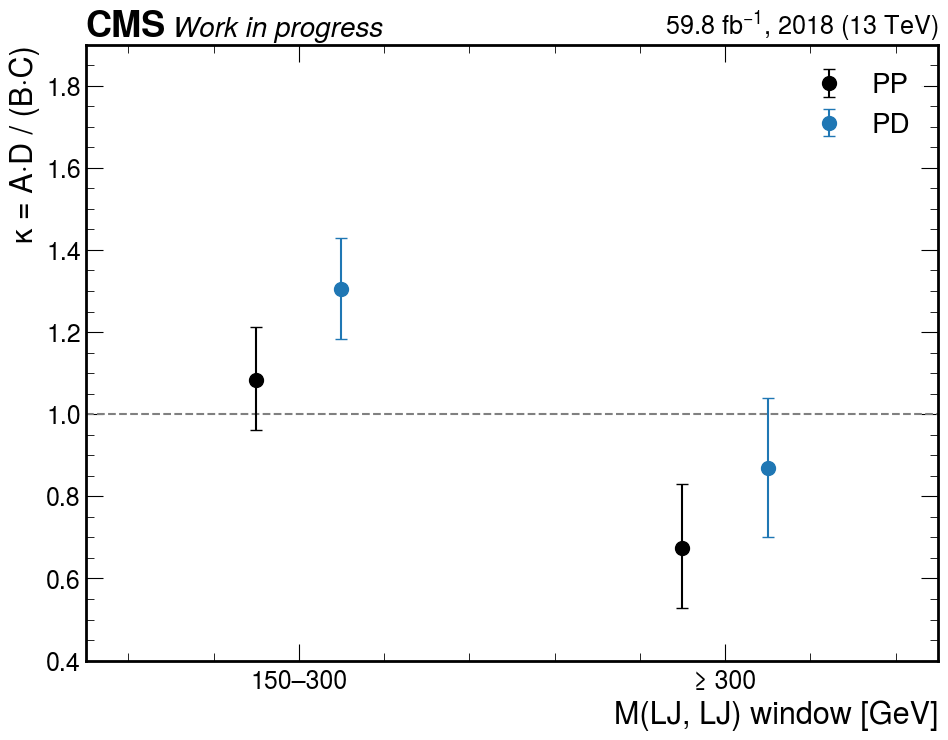

,plane,bin,A,B,C,D,kappa,A/B
0,PP,150-200,292,518,82,171,1.18 -0.18 +0.20,0.56 -0.04 +0.04
1,PP,200-300,306,575,73,136,0.99 -0.17 +0.18,0.53 -0.04 +0.04
2,PP,300-400,121,272,29,44,0.67 -0.19 +0.20,0.44 -0.05 +0.05
3,PP,400-600,52,133,15,24,0.63 -0.25 +0.29,0.39 -0.06 +0.08
4,PP,>=600,26,47,3,4,0.74 -0.74 +1.02,0.55 -0.13 +0.17
5,PP,all,,,,,0.97 ± 0.10,chi2 of the bins 3.9 / 4
6,PD,150-200,574,530,171,199,1.26 ± 0.16,1.08 -0.07 +0.07
7,PD,200-300,494,519,105,155,1.41 ± 0.21,0.95 -0.06 +0.06
8,PD,300-400,171,211,43,42,0.79 ± 0.21,0.81 -0.08 +0.09
9,PD,400-600,79,120,19,33,1.14 -0.40 +0.44,0.66 -0.09 +0.11


In [11]:
MASS = nl.kappa_table(d2, [nl.VR(f"{p}, {w}", "this analysis", p[0], p[1], mass=m)
                           for p in ("PP", "PD") for w, m in (("150–300", (150.0, 300.0)), ("≥ 300", (300.0, None)))], NOMINAL)
display(nl.kappa_view(MASS))
fig = npl.kappa_mass_figure({p: [(r["kappa"], r["minus"], r["plus"]) for _, r in MASS[MASS["region"].str.startswith(p)].iterrows()]
                             for p in ("PP", "PD")}, ["150–300", "≥ 300"])
plt.show()
display(ps.mass_table(d2, NOMINAL, planes=("PP", "PD")))

### 7e. The borrowed-factor premise: is PD's sideband ratio DD's?

The borrowed-factor routes of section 9 take a ratio from PD and apply it to DD. One of the
premises they rest on can be tested without opening A: C/D, the isolation pass/fail ratio among
events that fail |Δφ|, compared between the two planes. This is a comparison between planes, not a
test of independence inside DD (that would be A/B = C/D within DD, which needs A), and the direct
estimate does not depend on it: it uses DD's own C/D. The B route does: A/B of PD equals κ_PD × C/D
of PD, so B × (A/B)_PD is right for DD only if both κ and C/D transfer from PD to DD. DD over PD:
0.73 -0.22 +0.31 above 150 GeV (0.54 -0.19 +0.28 in 150–300 GeV, 2.23 -1.40 +3.72 above 300 GeV); per DSA class 0.89 -0.34 +0.51
(`dsa0`) and 0.62 -0.34 +0.57 (`dsa1+`). C/D does not transfer at the central value, 0.73, and the interval reaches one only at its upper edge. With
DD's own C/D, the B route's 61 events therefore require κ_DD = 1.34. In 150–300 GeV
alone the ratio reads 0.54 -0.19 +0.28, 1.6 standard deviations low, the window where the direct and
the B-route predictions differ most (section 10).

In [12]:
SB = bl.sideband_test_table(d2, NOMINAL, [(">=150", (150.0, None)), ("150-300", (150.0, 300.0)), (">=300", (300.0, None))])
display(SB.drop(columns=["ratio", "ratio minus", "ratio plus"]))

,bin,class,C/D DD,C/D PD,C/D of DD,C/D of PD,DD over PD
0,>=150,all,17/29,347/433,0.59 -0.17 +0.24,0.80 -0.06 +0.06,0.73 -0.22 +0.31
1,>=150,dsa0,12/16,301/359,0.75 -0.27 +0.43,0.84 -0.07 +0.07,0.89 -0.34 +0.51
2,>=150,dsa1+,5/13,46/74,0.38 -0.19 +0.35,0.62 -0.12 +0.14,0.62 -0.34 +0.57
3,150-300,all,11/26,276/354,0.42 -0.15 +0.22,0.78 -0.06 +0.07,0.54 -0.19 +0.28
4,150-300,dsa0,8/15,237/300,0.53 -0.22 +0.37,0.79 -0.07 +0.07,0.68 -0.29 +0.47
5,150-300,dsa1+,3/11,39/54,0.27 -0.16 +0.34,0.72 -0.15 +0.19,0.38 -0.24 +0.48
6,>=300,all,6/3,71/79,2.00 -1.20 +3.32,0.90 -0.15 +0.17,2.23 -1.40 +3.72
7,>=300,dsa0,4/1,64/59,4.00 -3.09 +24.45,1.08 -0.19 +0.24,3.69 -2.96 +22.55
8,>=300,dsa1+,2/2,7/20,1.00 -0.77 +3.40,0.35 -0.15 +0.24,2.86 -2.86 +9.78


## 8. The systematic uncertainty from the validation regions

The rule, written after the regions above were measured (so it is not blind to their values):

> Among the validation regions at our working point that differ from the search region only in
> the displacement of one or both lepton jets, the mass window, or the band of the partner's
> isolation, and whose κ is measured to 20% or better, take for each the larger of |κ − 1| and the
> uncertainty facing one, and quote the largest of those.

"The uncertainty facing one" is the side of κ's 68% interval that points towards one; "measured to
20% or better" means that the larger side of the interval is at most 20% of κ. The table lists
every region: ours (PP, PD and its two egamma types, DP, DD below 150 GeV) and Dongyub Lee's seven
at our working point, sorted by the number of respects in which each differs from the search
region. 9 of the 13 rows qualify, 8 distinct regions (V1 at our working point is PP):
PD, V2, V3, V7, PP, V1, V5, V4, V6.

The photon-only part of PD (PD:g, κ = 1.27 ± 0.12) is excluded by the rule's letter: it is a
sub-population of PD selected on the egamma LJ type, not a region of the plane. Whether the
inclusive κ is the right comparator depends on how much of the prediction each egamma type
carries, not on how many events it has. In DD, B·C/D per type is 46.0 events for the
photon-only LJs and 1.8 for the electron ones, so the photon-only LJs carry 96% of
the direct prediction in DD against 84% in PD. Applying PD's κ per egamma type to DD's
prediction per type, 1.27 × 46.0 + 0.77 × 1.8 ≈ 60 events, gives 1.31 times the direct
estimate, a number that rests on DD's 9/1/5 electron LJs in B/C/D. The same reweighting by
the muon LJ's DSA class (section 7c) gives 1.11. The two reweightings pull in opposite
directions, by egamma type to 1.31 and by DSA class to 1.11, and the inclusive
1.20 sits between them. The rule takes the inclusive value, 20%; admitting PD:g
as a region would give 27%, and taking the type reweighting at face value 31%. That
choice, 20% against 27–31%, is put to the group.

**Result: PD, 20%, ± 9 events.** The next largest qualifying value is V2 (13%).

Shown for comparison, not adopted:

* the quadrature form, √(|κ − 1|² + σ²): 22% (± 10 events);
* admitting the imprecise regions: DD < 150 gives 44% (± 20 events);
* the 33% of `estimate.ipynb` (± 15 events).

The 2μ2e background in the one-bin search region:

**46 ± 15 (stat.) ± 9 (syst.) events.**

*How to read the figure:* κ per region at our working point, ordered from the regions closest to
the search region (fewest differences, in brackets) to the farthest; filled circles qualify for the
rule, open circles (PD:g, PD:e, DP, DD below 150 GeV) do not; the green band is 1 ± 20%, the
dashed line κ = 1.

,region,WP,definition,kappa,|kappa - 1|,sigma (facing 1),precision,"max(|kappa - 1|, sigma)",differs from the search region in,qualifies
0,PD,ours,"P / D, egamma iso < 0.5, M ≥ 150 GeV",1.20 ± 0.10,0.20,0.10,8%,0.20,muon-LJ displacement,yes
1,DP,ours,"D / P, egamma iso < 0.5, M ≥ 150 GeV",1.02 -0.41 +0.48,0.02,0.41,47%,0.41,egamma-LJ displacement,no: precision 47% > 20%
2,DD < 150,ours,"D / D, egamma iso < 0.5, M < 150 GeV",1.26 ± 0.44,0.26,0.44,35%,0.44,mass window,no: precision 35% > 20%
3,PP,ours,"P / P, egamma iso < 0.5, M ≥ 150 GeV",0.97 ± 0.10,0.03,0.10,10%,0.10,"muon-LJ displacement, egamma-LJ displacement",yes
4,PD:g,ours,"P / D:g, egamma iso < 0.5, M ≥ 150 GeV",1.27 ± 0.12,0.27,0.11,9%,0.27,"muon-LJ displacement, split g",no: differs in split g
5,PD:e,ours,"P / D:e, egamma iso < 0.5, M ≥ 150 GeV",0.77 ± 0.20,0.23,0.20,26%,0.23,"muon-LJ displacement, split e",no: differs in split e; precision 26% > 20%
6,V1,ours,"P / P, egamma iso < 0.5, M ≥ 150 GeV",0.97 ± 0.10,0.03,0.10,10%,0.10,"muon-LJ displacement, egamma-LJ displacement",yes
7,V5,ours,"P / any, egamma iso 0.2–1, M ≥ 150 GeV",1.05 ± 0.08,0.05,0.08,8%,0.08,"muon-LJ displacement, egamma-LJ displacement, partner-isolation band",yes
8,V6,ours,"P / any, egamma iso 0.15–1, M ≥ 150 GeV",1.03 ± 0.07,0.03,0.07,7%,0.07,"muon-LJ displacement, egamma-LJ displacement, partner-isolation band",yes
9,V7,ours,"P / P, egamma iso 0.15–1, M ≥ 150 GeV",1.03 ± 0.10,0.03,0.10,10%,0.10,"muon-LJ displacement, egamma-LJ displacement, partner-isolation band",yes


rule: 20% from PD; quadrature 22%; imprecise regions admitted 44% from DD < 150
estimate: 45.7 ± 14.9 (stat.) ± 9.0 (syst.) events


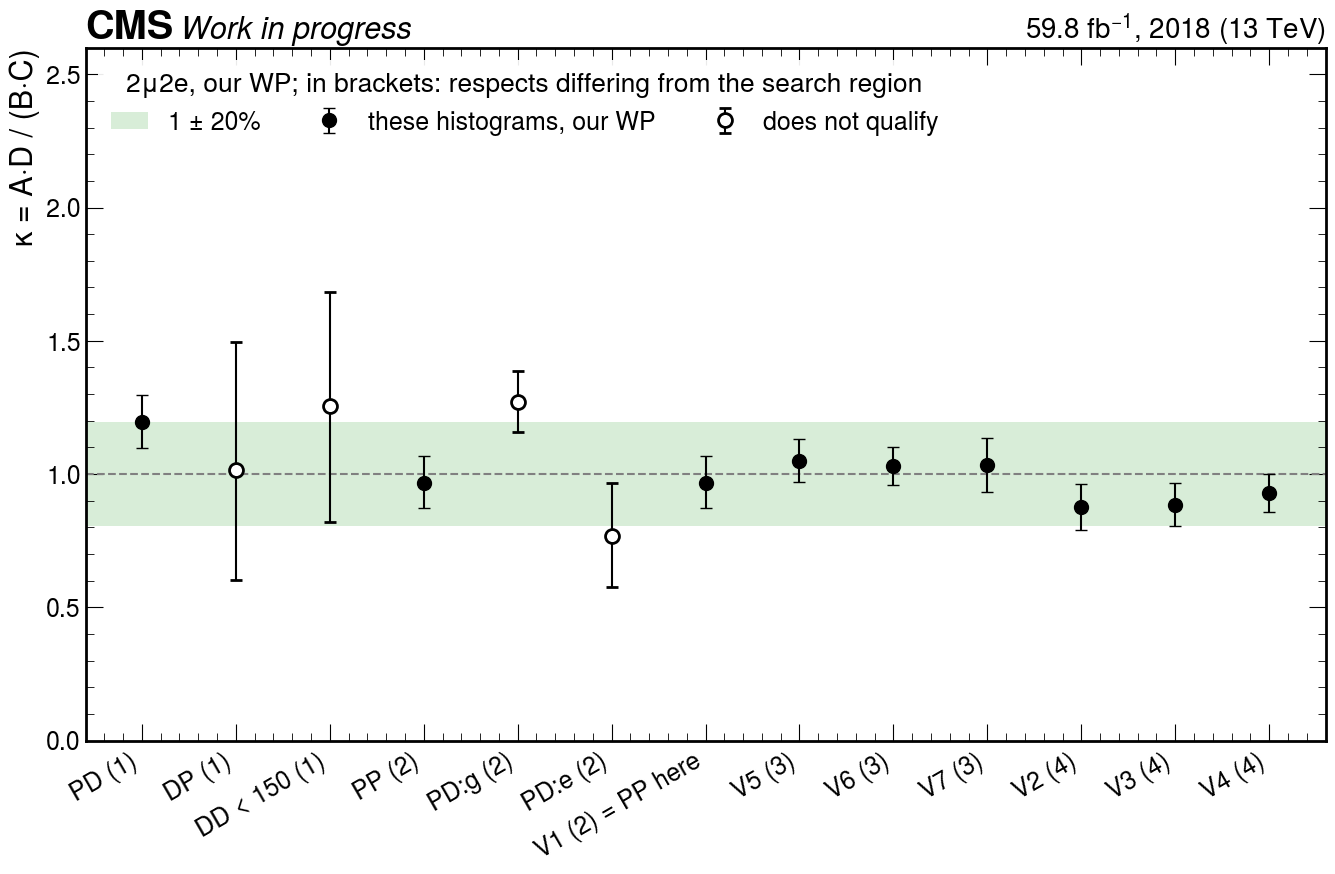

In [13]:
SYS = nl.systematic_table(d2, nl.our_vrs() + nl.DONGYUB_VRS)
display(nl.systematic_view(SYS))
SYST, SYST_FROM = nl.closure_systematic(SYS)
QUAD, _ = nl.closure_systematic(SYS, "quadrature")
ALT, ALT_FROM = nl.closure_systematic(SYS, qualifying=False)
EST = nl.kappa_row(d2, nl.SR, NOMINAL)
print(f"rule: {nl.pct(SYST)} from {SYST_FROM}; quadrature {nl.pct(QUAD)}; imprecise regions admitted {nl.pct(ALT)} from {ALT_FROM}")
print(f"estimate: {EST['B C/D']:.1f} ± {EST['B C/D err']:.1f} (stat.) ± {EST['B C/D'] * SYST:.1f} (syst.) events")
points, labels = npl.table_points(SYS)
SAME_AS_PP = nl.same_regions(SYS, "PP")
labels = [f"{r} ({n})" + (" = PP here" if r in SAME_AS_PP else "") for r, n in zip(labels, SYS["n differences"])]
fig = npl.kappa_points_figure(points, labels, "2μ2e, our WP; in brackets: respects differing from the search region",
                              "nominal_kappa_systematic", band=SYST, band_label=f"1 ± {nl.pct(SYST)}", ylim=(0, 2.6),
                              hollow_label="does not qualify")
plt.show()

## 9. Cross-check: the three borrowed-factor routes

`estimate.ipynb` estimated A of DD three more ways, each by borrowing a ratio from PD per DSA class
and summing: B × (A/B), C × (A/C) and D × (A/D) give 61.3 ± 8.0, 59.7 ± 15.6 and 71.7 ± 15.3 events. Their spread
is not a systematic uncertainty: they share DD's sidebands with the direct estimate, and each
assumes that a ratio of PD transfers to DD. The B route holds if A/B itself transfers from PD to
DD. A/B of PD is κ_PD × C/D of PD, and DD's C/D is 0.73 -0.22 +0.31 times PD's (section 7e), so with DD's own
C/D the B route's 61 events require κ_DD = 1.34. The C and D routes likewise assume that
A/C and A/D transfer. The two estimates differ by 16 events, 0.9 of the combined
statistical and systematic uncertainty of the direct estimate.

If the search plane's κ were PD's, A would be 1.20 × 45.7 ≈ 55 events, or
1.24 × 33.0 + 0.73 × 13.1 ≈ 51 with PD's κ per DSA class applied to DD's prediction per class; 61
assumes more than that.

The earlier notebooks made the B route the headline and the direct estimate a cross-check. This
one does the opposite: with Dongyub Lee's regions added, the validation regions favour κ = 1 within
20%, and the one 2.0σ deviation, PD, is carried by the systematic.

In [14]:
display(el.routes_table(d2, WINDOWS))
display(el.class_factors_table(d2, WINDOWS[:1]))

,window,DD B/C/D,direct B C/D,B x A/B per class,B x A/B inclusive,C x A/C per class,C x A/C inclusive,D x A/D per class,D x A/D inclusive,DD A observed
0,M >= 150,78/17/29,45.7 ± 14.9,61.3 ± 8.0,74.8 ± 9.0,59.7 ± 15.6,65.8 ± 16.5,71.7 ± 15.3,89.9 ± 17.5,blind
1,150-300,52/11/26,22.0 ± 8.5,41.2 ± 6.6,52.9 ± 7.7,39.2 ± 12.7,42.6 ± 13.2,64.8 ± 14.4,78.4 ± 16.2,blind
2,M >= 300,26/6/3,52.0 ± 38.2,18.6 ± 4.2,20.3 ± 4.4,20.8 -9.2 +9.7,23.2 ± 10.1,6.0 ± 4.7,10.4 ± 6.2,blind


,window,class,DD B/C/D,PD A/B/C/D,A/B PD,A/C PD,A/D PD,C/D PD,C/D DD,C/D DD over PD
0,M >= 150,dsa0,44/12/16,1253/1203/301/359,1.04 ± 0.04,4.16 -0.27 +0.29,3.49 -0.21 +0.22,0.84 -0.07 +0.07,0.75 -0.27 +0.43,0.89 -0.34 +0.51
1,M >= 150,dsa1+,34/5/13,90/198/46/74,0.45 -0.06 +0.07,1.96 -0.35 +0.43,1.22 -0.19 +0.22,0.62 -0.12 +0.14,0.38 -0.19 +0.35,0.62 -0.34 +0.57
2,M >= 150,all,78/17/29,1343/1401/347/433,0.96 ± 0.04,3.87 -0.23 +0.25,3.10 -0.17 +0.18,0.80 -0.06 +0.06,0.59 -0.17 +0.24,0.73 -0.22 +0.31


## 10. What would settle it: opening 150–300 GeV of the search plane

The direct test of κ in the search plane is to open A of DD in a window where the signal is small.
The background predicted there (direct, and B route):

* 150–200 GeV: 10.5 ± 5.4 (B route 23.9 ± 5.3);
* 200–300 GeV: 12.0 ± 7.0 (B route 17.7 ± 4.3);
* 150–300 GeV: 22.0 ± 8.5 (B route 41.2 ± 6.6).

The two predictions for 150–300 GeV differ by a factor 1.9: the direct one uses DD's own
C/D in the window (52/11/26 events in B/C/D), the B route uses PD's A/B. Their ratio is the
product of two factors: PD's κ per DSA class weighted by the search plane's B, 1.02 here,
and the sideband ratio (C/D)_PD / (C/D)_DD, 1.84 (the inverse of the 0.54 -0.19 +0.28 of section
7e). The first is close to one, so the factor between the predictions is almost all sideband ratio.
A count near the first prediction would say that DD's own sidebands are right there; one near the
second, that the direct route under-predicts the window. The two predictions are 1.8
standard deviations apart if treated as independent, about 2.2 once the shared B is
accounted for (both scale with DD's B, with different factors), so the window can tell them apart, but not sharply. κ of DD in the
window would be measured to about 44% (21% from A's count alone, the
rest from B, C and D), which separates 1.0 from 1.9 but not from 1.2; and section 7d shows
that κ changes with the mass, so the window's κ is not the search region's. 150–200 GeV alone
would measure it to about 60%. The window is the only direct test there is; it is
not a sharp one.

The price is signal. Of the 90 2μ2e signal points, the 15 with a 200 GeV mediator put
45%–71% of their search-region yield in 150–200 GeV and 97%–100% in 150–300 GeV (yields
0.00–0.56 events at the stored cross section; 0.0%–2.2% more below 150 GeV, in the
already-open DD validation region). The heavier points (500, 800, 1000 GeV) put at most
5.6% in 150–300 GeV; the 800 GeV, 0.25 GeV, 0.25 mm point, for example, has 58.8
events, 0.0% of them below 300 GeV and 97.4% at ≥ 600 GeV. Opening 150–300 GeV ends the
200 GeV search; opening 150–200 GeV costs about half of it. The decision is the group's.

The table also lists the 100 and 150 GeV mediators. These masses are outside the range the
analysis targets (the group's grid of interest starts at 200 GeV) and are kept in the table for
completeness. For them much or most of the signal in A of DD sits below 150 GeV (86–98% at 100 GeV, 39–100% at 150 GeV),
so DD below 150 GeV, used here as a validation region, would be signal-contaminated for those
hypotheses.

*How to read the figure:* one bar per signal point (the 200 GeV points and the seven points of
`estimate.ipynb`), split into the share of its search-region yield in each mass bin; the label
gives the mediator mass, dark-photon mass and decay length, and the yield in brackets
(simulation).

,window,DD B/C/D,direct B C/D,B x A/B per class,DD A observed
0,150-200,28/6/16,10.5 ± 5.4,23.9 ± 5.3,blind
1,200-300,24/5/10,12.0 ± 7.0,17.7 ± 4.3,blind
2,150-300,52/11/26,22.0 ± 8.5,41.2 ± 6.6,blind


90 2mu2e signal points; share of the search-region yield per mass bin, min-max per mediator mass, and the yields in A of DD above and below 150 GeV in events


,mediator mass [GeV],points,150-200,200-300,150-300,>=600,"yield, M ≥ 150 [events]","yield, M < 150 [events]"
0,100,15,0–100%,0–100%,97–100%,0–0%,0.00–0.02,0.00–0.45
1,150,15,80–100%,0–19%,99–100%,0–0%,0.00–3.36,0.00–2.68
2,200,15,45–71%,29–53%,97–100%,0–0%,0.00–0.56,0.00–0.00
3,500,15,0–0%,0–5%,0–5%,2–17%,0.01–14.86,0.00–0.00
4,800,15,0–0%,0–6%,0–6%,93–100%,0.05–63.10,0.00–0.00
5,1000,15,0–0%,0–0%,0–0%,94–100%,0.00–2.05,0.00–0.00


,point,yield,150-200,200-300,300-400,400-600,>=600,150-300,below
2,2Mu2E_1000GeV_0p25GeV_0p2mm,1.480,0.000,0.000,0.001,0.006,0.993,0.000,0.000
7,2Mu2E_1000GeV_1p2GeV_0p96mm,2.051,0.000,0.000,0.002,0.017,0.980,0.000,0.000
45,2Mu2E_200GeV_0p25GeV_0p01mm,0.009,0.508,0.492,0.000,0.000,0.000,1.000,0.000
46,2Mu2E_200GeV_0p25GeV_0p1mm,0.109,0.521,0.478,0.002,0.000,0.000,0.998,0.000
47,2Mu2E_200GeV_0p25GeV_10p0mm,0.117,0.459,0.521,0.020,0.000,0.000,0.980,0.000
48,2Mu2E_200GeV_0p25GeV_1p0mm,0.563,0.475,0.517,0.007,0.001,0.000,0.992,0.001
49,2Mu2E_200GeV_0p25GeV_5p0mm,0.231,0.459,0.530,0.010,0.001,0.000,0.989,0.001
50,2Mu2E_200GeV_1p2GeV_0p048mm,0.001,0.625,0.375,0.000,0.000,0.000,1.000,0.000
51,2Mu2E_200GeV_1p2GeV_0p48mm,0.041,0.543,0.453,0.002,0.002,0.000,0.996,0.000
52,2Mu2E_200GeV_1p2GeV_24p0mm,0.123,0.471,0.515,0.012,0.001,0.000,0.987,0.001


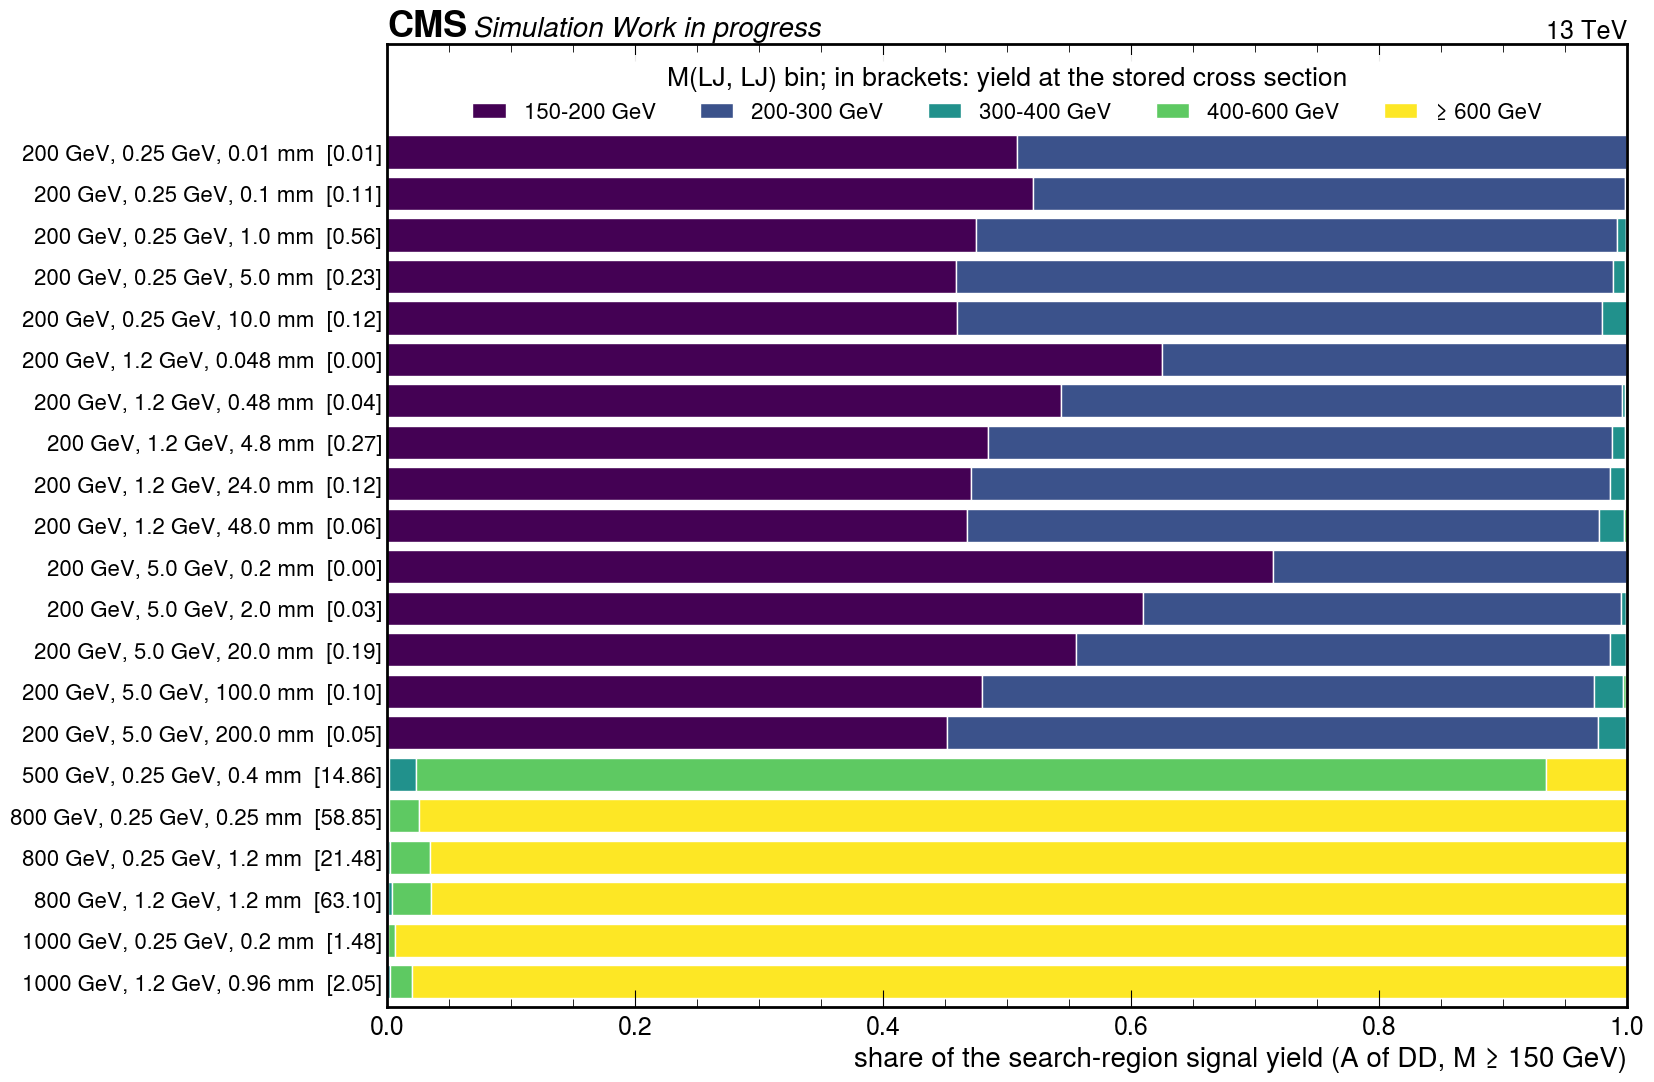

In [15]:
OPEN = [(label, bl.bin_cfg(NOMINAL, lo, hi)) for label, (lo, hi) in (("150-200", (150.0, 200.0)), ("200-300", (200.0, 300.0)), ("150-300", (150.0, 300.0)))]
display(el.routes_table(d2, OPEN)[["window", "DD B/C/D", "direct B C/D", "B x A/B per class", "DD A observed"]])
NAMES = sorted(os.path.basename(p)[: -len(".coffea")] for p in tl.sample_paths(BASE, "signal")
               if os.path.basename(p).startswith("2Mu2E_"))
SIGNAL = nl.signal_share_table(bl.signal_profiles(BASE, NAMES, "2mu2e", NOMINAL, plane="DD", region="A"))
print(f"{len(SIGNAL)} 2mu2e signal points; share of the search-region yield per mass bin, min-max per mediator mass, "
      "and the yields in A of DD above and below 150 GeV in events")
display(nl.share_summary(SIGNAL))
SHOWN = SIGNAL[SIGNAL["point"].str.startswith("2Mu2E_200GeV_") | SIGNAL["point"].isin(bl.SIGNAL_POINTS["2mu2e"])]
display(SHOWN.round(3))
fig = npl.signal_share_figure(SHOWN.reset_index(drop=True))
plt.show()

## 11. 4μ in one section

In 4μ the search plane holds 2/1/3/3 events in A/B/C/D below 150 GeV and 3/0/0 in B/C/D above
it: no κ of the search plane can be measured, and no B·C/D exists above 150 GeV (C and D are
empty). `estimate.ipynb` (section 5.2) gives six count-limited readings from the open neighbouring
regions, by B of DD above 150 GeV times A/B of a plane below it, and by A of DD below 150 GeV times
the above/below ratio of the neighbouring regions: they read 1.1–2.3 events, median
1.5, each with a 58–78% statistical error, so the 4μ background is uncertain by a factor
two to three. Of the open DD events, 0 have both muon LJs made only of DSA muons, the
signature of the instrumental background seen in July 2026 before the cosmic and spread cuts.

Dongyub Lee's 4μ regions (quoted from his slides): the isolation × isolation plane fails
(4.66 ± 0.54), the muon-isolation × |Δφ| plane closes (1.06 ± 0.18) but its κ runs over
0.3–1.3 below 150 GeV and 0.75 to above 2 above as the isolation boundary moves.

Nothing more can be done with these counts. What the factor costs: for one observed event the 95%
CL upper limit on a signal count moves 4.3 → 3.6 (17%) as the background runs over 0.6–3.7 events, for two
5.7 → 4.3 (26%) (a counting experiment with a known background, `estimate_lib.counting_limit`).

In [16]:
HIGH4, LOW4 = ("M >= 150", NOMINAL), ("M < 150", LOW)
display(el.count_grid(d4, [LOW4, HIGH4], "DD", [f"dsa{a}:subdsa{b}" for a in ("0", "1", "2+") for b in ("0", "1", "2+")]))
print("B of the search plane above 150 GeV times A/B of the planes whose A is open")
display(el.sideband_transfer_table(d4, HIGH4, LOW4))
print("A of the DD plane below 150 GeV times the above/below-150 GeV ratio of the open neighbouring regions")
display(el.mass_transfer_table(d4, HIGH4, LOW4))
print("95% CL upper limit on a signal count for n observed events and an expected background b")
display(el.counting_limit_table((0, 1, 2), (0.5, 1.0, 1.7, 3.0, 4.5)))

,window,region,total,dsa0:subdsa0,dsa0:subdsa1,dsa0:subdsa2+,dsa1:subdsa0,dsa1:subdsa1,dsa1:subdsa2+,dsa2+:subdsa0,dsa2+:subdsa1,dsa2+:subdsa2+
0,M < 150,A,2,0,0,0,2,0,0,0,0,0
1,M < 150,B,1,0,0,0,0,1,0,0,0,0
2,M < 150,C,3,0,0,0,0,2,0,1,0,0
3,M < 150,D,3,1,0,0,1,1,0,0,0,0
4,M >= 150,A,blind,blind,blind,blind,blind,blind,blind,blind,blind,blind
5,M >= 150,B,3,0,1,0,1,0,0,0,1,0
6,M >= 150,C,0,0,0,0,0,0,0,0,0,0
7,M >= 150,D,0,0,0,0,0,0,0,0,0,0


B of the search plane above 150 GeV times A/B of the planes whose A is open


,reference plane,"A, B (M < 150)",A/B (M < 150),A/B (M >= 150),DD B (M >= 150),estimate of DD A (M >= 150)
0,DP,"30, 39",0.77 -0.18 +0.24,blind,3,2.31 ± 1.51
1,PD,"15, 41",0.37 -0.11 +0.15,blind,3,1.10 -0.71 +0.78
2,PP,"332, 725",0.46 -0.03 +0.03,0.76 -0.06 +0.07,3,1.37 ± 0.80


A of the DD plane below 150 GeV times the above/below-150 GeV ratio of the open neighbouring regions


,reference region,N (M >= 150),N (M < 150),ratio,DD A (M < 150),estimate of DD A (M >= 150)
0,PP A,264,332,0.80 -0.07 +0.07,2,1.59 ± 1.13
1,DP B,34,39,0.87 -0.20 +0.26,2,1.74 ± 1.34
2,PD B,25,41,0.61 -0.15 +0.20,2,1.22 ± 0.95


95% CL upper limit on a signal count for n observed events and an expected background b


,observed,b = 0.5,b = 1,b = 1.7,b = 3,b = 4.5
0,0,3.00,3.00,3.00,3.00,3.00
1,1,4.36,4.11,3.89,3.64,3.49
2,2,5.82,5.41,4.97,4.44,4.08


## 12. Summary and to-do list

* The 2μ2e background in the one-bin search region is **46 ± 15 (stat.) ± 9 (syst.) events**, the search plane's
  own B·C/D.
* κ closes in PP (0.97 ± 0.10) and in Dongyub Lee's seven regions at his working point (the two codes
  agree to the printed digit in 6 of 7); DP (1.02 -0.41 +0.48) and DD below 150 GeV (1.26 ± 0.44) are
  consistent with one but imprecise.
* PD is 20% above one (1.20 ± 0.10), carried by photon-only egamma LJs (1.27 ± 0.12); DD's sidebands
  are as photon-rich as PD's. PD sets the systematic: 20% by the rule; 27–31% if the photon-only sub-population is taken as the carrier (the choice is put to the group).
* κ depends on the working point (V2–V4: 1.01–1.02 at his, 0.87–0.93 at ours) and falls
  with the mass (2.9 standard deviations from 150–300 GeV to above 300 GeV). For one bin the
  integrated κ is the right test as long as the validation planes' mass distributions resemble the
  search plane's (90% of DD's D in 150–300 GeV, 82% of PD's); for a binned search
  region it is an effect of up to 33% per window.
* The B route (61 events) is the cross-check; it holds if A/B transfers from PD, which with DD's
  own C/D requires κ_DD = 1.34. With PD's κ itself, A would be 55 (51 per DSA
  class).
* 4μ: about 1.5 events, uncertain by a factor two to three; nothing more to do.

To do, for the group:

1. Fix the blinding box: Dongyub Lee's histograms carry the data in the search region unblinded.
2. Dongyub to reproduce κ_PD from his 6D histograms, and to split his validation regions above
   150 GeV at 300 or 400 GeV.
3. State the criterion by which the working point is chosen.
4. Decide whether to open 150–300 GeV (or 150–200 GeV) of the search plane as a validation region.
5. Adopt the direct ABCD with the validation-region systematic as the convention.

## Appendix: reproducibility

The data are read only through `transfer_lib.summed_cubes(BASE, "data", prefix="abcd8d")`,
which sums the merged 8D histograms and sets the hidden box (iso0<0.25 iso1<0.5 mass>=150 dphi>=2.4 planes=[('2mu2e', ('displaced', 'displaced')), ('4mu', ('displaced', 'displaced')), ('4mu', ('displaced', 'prompt')), ('4mu', ('prompt', 'displaced'))]) to NaN before anything is
cached or returned; every projection touching a hidden cell is NaN and prints as "hidden". The
signal shares of section 10 read the signal histograms one point at a time
(`binning_lib.signal_profiles`; simulation is never hidden). Code: `nominal_lib.py` (validation
regions, the systematic rule, the plane histogram, the shares), `nominal_plots.py` (the figures),
`_build_nominal.py` (writes this notebook and computes every number in its text with the same
functions), `test_nominal_lib.py` (tests on synthetic histograms). On the LPC:
`python _build_nominal.py` then `jupyter nbconvert --to notebook --execute --inplace
nominal.ipynb` in `sidm_venv`.